# Olist E-Commerce Data Analysis

This notebook analyzes the Olist Brazilian E-Commerce dataset (2016–2018), covering customers, orders, order items, payments, reviews, products, sellers, and geolocation.

**Business questions addressed:**
- How has order volume and revenue evolved over time?
- Which customers are the most valuable, and which are at risk of churning? (RFM segmentation)
- How does delivery performance affect customer satisfaction?

## 1. Import Libraries

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

## 2. Load Data

In [6]:

customers = pd.read_csv("olist_customers_dataset.csv")
geolocation = pd.read_csv("olist_geolocation_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_payments = pd.read_csv("olist_order_payments_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
orders = pd.read_csv("olist_orders_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
category_translation = pd.read_csv("product_category_name_translation.csv")

print("All files have been uploaded successfully!")

All files have been uploaded successfully!


## 3. Overview of Table Sizes

In [7]:
tables = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "order_payments": order_payments,
    "order_reviews": order_reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation,
}

for name, df in tables.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

customers: 99441 rows, 5 columns
geolocation: 1000163 rows, 5 columns
order_items: 112650 rows, 7 columns
order_payments: 103886 rows, 5 columns
order_reviews: 99224 rows, 7 columns
orders: 99441 rows, 8 columns
products: 32951 rows, 9 columns
sellers: 3095 rows, 4 columns
category_translation: 71 rows, 2 columns


*Note: the `geolocation`, `sellers`, and `products` tables are loaded and quality-checked below for completeness, but are not used in the analyses that follow — those focus on order timing, customer value segmentation, and delivery satisfaction.*

## 4. Data Overview

### Preview of Key Tables

In [8]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [10]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### Missing Values

In [11]:
for name, df in tables.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(f"\n---{name}---")
        print(missing)


---order_reviews---
review_comment_title      87656
review_comment_message    58247
dtype: int64

---orders---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

---products---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


### Duplicate Rows

In [12]:
for name, df in tables.items():
    duplicate_count = df.duplicated().sum()
    print(f"{name}: {duplicate_count} duplicate rows")

customers: 0 duplicate rows
geolocation: 261831 duplicate rows
order_items: 0 duplicate rows
order_payments: 0 duplicate rows
order_reviews: 0 duplicate rows
orders: 0 duplicate rows
products: 0 duplicate rows
sellers: 0 duplicate rows
category_translation: 0 duplicate rows


### Data Types & Conversion

In [13]:
for name, df in tables.items():
    print(f"\n---{name}---")
    print(df.dtypes)


---customers---
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

---geolocation---
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

---order_items---
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

---order_payments---
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

---order_reviews---
review_id                    str
order_id                     str
review_score               int64
revie

In [14]:
date_columns = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "shipping_limit_date"
    ],
    "order_reviews":[
        "review_creation_date",
        "review_answer_timestamp"
    ]   
}
for table_name, columns in date_columns.items():
    for column in columns:
        tables[table_name][column] = pd.to_datetime(
            tables[table_name][column],
            errors="coerce"
        )

In [15]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

## 5. Monthly Order Count

In [16]:
orders["year_month"] = orders["order_purchase_timestamp"].dt.to_period("M")

monthly_orders = (
    orders.groupby("year_month")["order_id"].nunique().reset_index(name="order_count")
)
monthly_orders

,year_month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


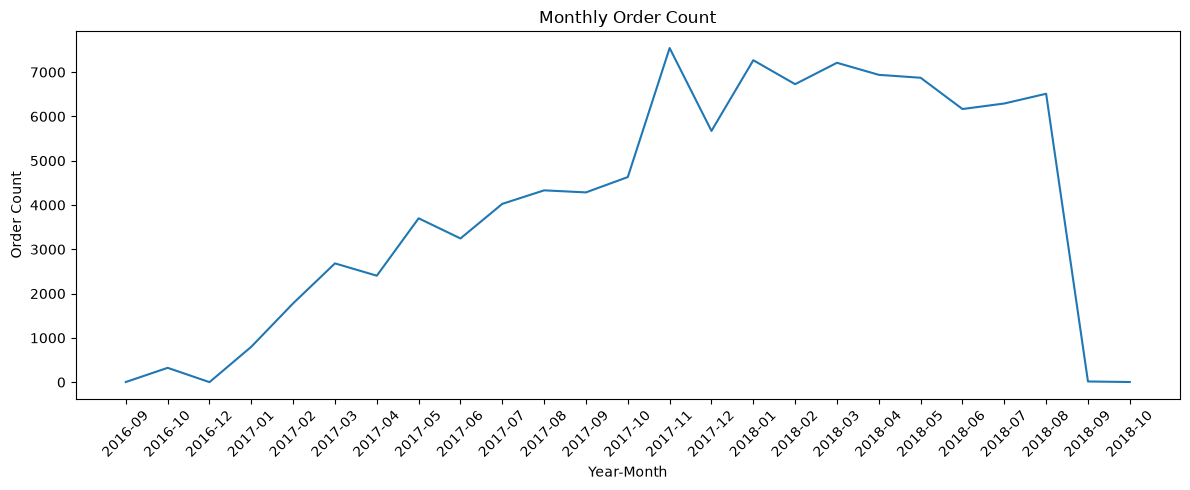

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
       monthly_orders["year_month"].astype(str),
       monthly_orders["order_count"]
)

plt.xlabel("Year-Month")
plt.ylabel("Order Count")
plt.title("Monthly Order Count")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Finding:** Monthly order counts were calculated to examine how orders changed over time. Order volume shows a clear increase throughout 2017, reaching its peak in November 2017 with 7,544 orders. In 2018, order volume generally remains high and more stable.

**Note:** The noticeable drop in September and October 2018 is likely due to an incomplete-period effect, since the dataset ends around that time — this should not be interpreted as an actual decline in sales.

## 6. Monthly Revenue Trend

In [18]:
order_revenue = order_items.groupby('order_id').agg(
    product_revenue=('price','sum'),
    freight_revenue=('freight_value','sum')
).reset_index()

order_revenue['total_revenue'] = (
    order_revenue['product_revenue'] +
    order_revenue['freight_revenue'])
        
order_revenue = order_revenue.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id', how='left')

order_revenue['order_purchase_timestamp'] = pd.to_datetime(order_revenue['order_purchase_timestamp'])
order_revenue['year_month'] = order_revenue['order_purchase_timestamp'].dt.to_period('M').astype(str)

In [19]:
monthly_revenue = order_revenue.groupby('year_month')['total_revenue'].sum().reset_index()

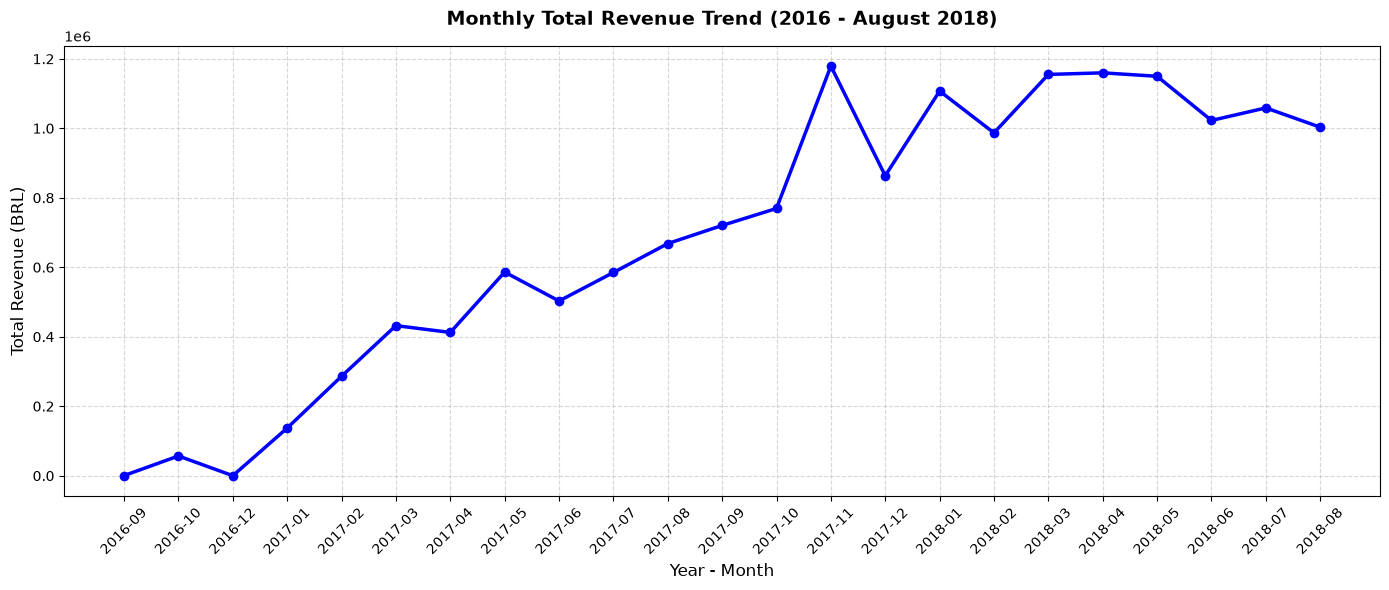

In [20]:
monthly_revenue_filtered = monthly_revenue[monthly_revenue['year_month'] < '2018-09'].copy()

monthly_revenue_filtered['year_month_str'] = monthly_revenue_filtered['year_month'].astype(str)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,6))
plt.plot(
    monthly_revenue_filtered['year_month_str'],
    monthly_revenue_filtered['total_revenue'],
        marker='o',
        color='blue',
        linewidth=2.5,
        markersize=6
   )     

plt.title('Monthly Total Revenue Trend (2016 - August 2018)', fontsize=14, fontweight='bold', pad =15)
plt.xlabel('Year - Month' , fontsize=12)
plt.ylabel('Total Revenue (BRL)' , fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## 7. RFM Customer Segmentation

In [21]:
import datetime as dt

ref_date = orders['order_purchase_timestamp'].max() + dt.timedelta(days=1)

rfm_df = orders.merge(order_items, on= 'order_id').merge(customers, on='customer_id')

rfm= rfm_df.groupby('customer_unique_id').agg({   
    'order_purchase_timestamp': lambda date : (ref_date - date.max()).days,
    'order_id':'nunique',
    'price' : 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id','Recency','Frequency','Monetary']

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,18.90
2,0000f46a3911fa3c0805444483337064,586,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,337,1,180.00


In [22]:
import pandas as pd

rfm['R_Score'] = pd.qcut(rfm['Recency'],5, labels=[5, 4,3, 2,1])

rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method = 'first'), 5, labels=[1, 2, 3, 4, 5])

rfm['M_Score'] = pd.qcut(rfm['Monetary'],5, labels=[1, 2, 3, 4, 5])

rfm['RFM_SCORE'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

seg_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At_risk',
    r'[1-2]5': 'Cant_Loose',
    r'3[1-2]': 'About_to_Sleep',
    r'33' : 'Need_Attention',
    r'[3-4][4-5]' : 'Loyal Consumers',
    r'41': 'Promising',
    r'51' : 'New_Customers',
    r'[4-5][2-3]': 'Potential_Loyalists',
    r'5[4-5]': ' Champions'
}

rfm['Segment'] = (rfm['R_Score'].astype(str) + rfm ['F_Score'].astype(str)).replace(seg_map, regex=True)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_SCORE,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,129.90,4,1,4,414,Promising
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,18.90,4,1,1,411,Promising
2,0000f46a3911fa3c0805444483337064,586,1,69.00,1,1,2,112,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,25.99,2,1,1,211,Hibernating
4,0004aac84e0df4da2b147fca70cf8255,337,1,180.00,2,1,5,215,Hibernating


In [23]:
rfm['Segment'].value_counts()

Segment
Loyal Consumers        15361
Potential_Loyalists    15336
Hibernating            15279
At_risk                15261
 Champions              7699
About_to_Sleep          7554
Cant_Loose              7436
Promising               3854
Need_Attention          3840
New_Customers           3800
Name: count, dtype: int64

C:\Users\EXCALIBUR\AppData\Local\Temp\ipykernel_17416\2256618097.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


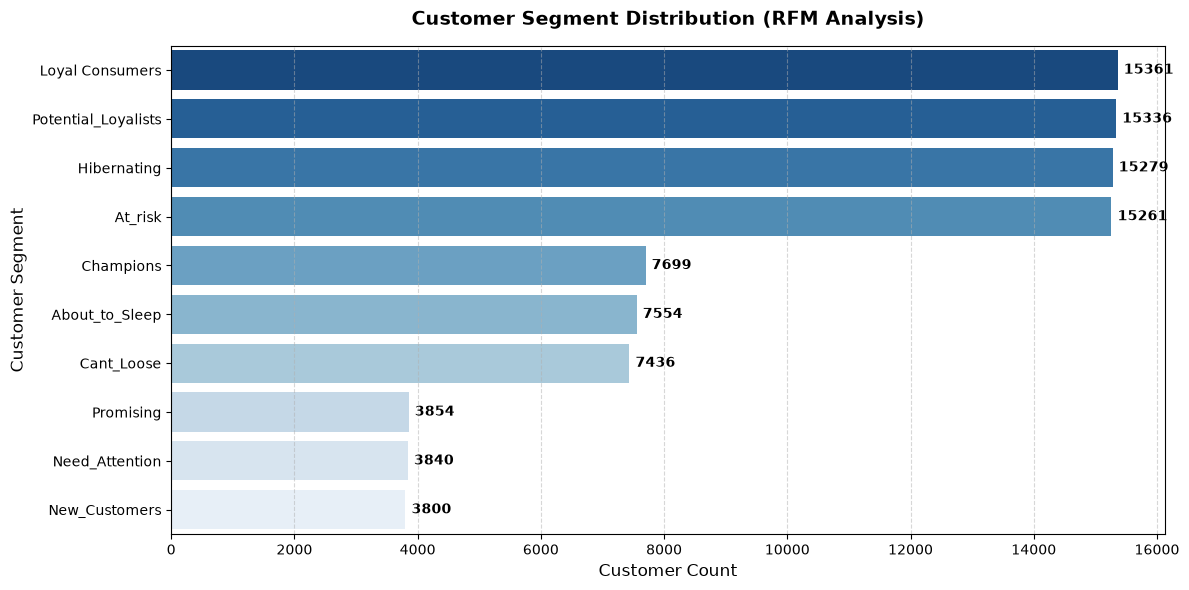

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(12,6))
sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index,
    palette='Blues_r'
)

plt.title('Customer Segment Distribution (RFM Analysis)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Count', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)
plt.grid(axis='x',linestyle='--',alpha=0.5)

for index, value in enumerate(segment_counts.values):
    plt.text(value + 100, index ,str(value), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Business Recommendations

### At Risk & Hibernating
**Status:** This large audience of approximately 30,000 customers is about to churn or has gone completely dormant.

**Action:** "We miss you" themed email/SMS campaigns and personalized, time-sensitive discount coupons (e.g., valid for 48 hours) should be used for win-back efforts.

### New Customers & Promising
**Status:** This is a high-potential group that has recently joined the platform.

**Action:** They should be moved to the loyal customer segment using onboarding email series that encourage a second purchase and cross-sell recommendations.

### Champions & Loyal Customers
**Status:** This is the core audience of the platform, consisting of the most valuable and frequent shoppers.

**Action:** Exclusive VIP loyalty programs, early access to new product categories, and personalized thank-you gifts should be offered.

## 8. Delivery & Customer Satisfaction Analysis

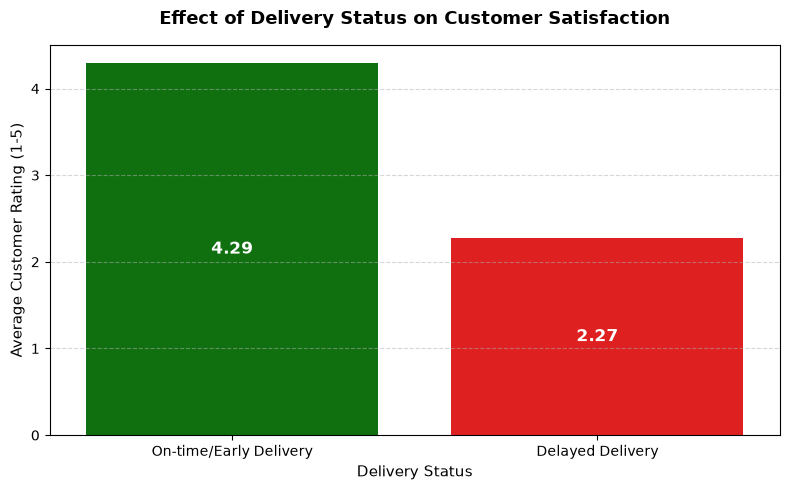

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

delivery_review = orders.merge(order_reviews, on='order_id')
delivery_review = delivery_review[delivery_review['order_status'] =='delivered'].copy()

delivery_review['delay_days'] = (
    delivery_review['order_delivered_customer_date'] - delivery_review['order_estimated_delivery_date']
).dt.days

delivery_review['delivery_status']= delivery_review['delay_days'].apply(
    lambda x: 'Delayed Delivery' if x > 0 else 'On-time/Early Delivery'
)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data= delivery_review,
    x='delivery_status',
    y='review_score',
    hue='delivery_status',
    palette=['green','red'],
    errorbar=None,
    legend=False
)

plt.title('Effect of Delivery Status on Customer Satisfaction', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Delivery Status', fontsize=11)
plt.ylabel('Average Customer Rating (1-5)', fontsize=11)
plt.grid(axis='y', linestyle='--',alpha=0.5)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2.,p.get_height()/2),
                ha='center', va='center', fontsize=12, fontweight='bold', color='white')

plt.tight_layout()
plt.show()

### Logistics & Customer Satisfaction Analysis

**Finding:** While the average satisfaction score for on-time deliveries is 4.29, this score drops by nearly half to 2.27 when deliveries are delayed.

**Business Recommendation:** To prevent customer churn and low ratings, it is critical to improve shipping/logistics processes, proactively notify customers of orders expected to be delayed, and introduce compensation coupons.

## Executive Summary

- **Order growth:** Order volume grew steadily through 2017, peaking in November 2017 at 7,544 orders, and remained high and stable through 2018 (the apparent drop in Sep–Oct 2018 reflects an incomplete data period, not an actual decline).
- **Revenue trend:** Monthly revenue follows a similar upward and then stable pattern, consistent with the order volume trend.
- **Customer segments (RFM):** A large group (~30,000 customers) is at risk or has gone dormant and needs win-back campaigns; new/promising customers should be nurtured toward loyalty; champions and loyal customers are the core revenue base and merit retention investment (VIP programs, early access, loyalty rewards).
- **Delivery impact:** Delivery delays have a strong negative effect on satisfaction — average review scores drop from 4.29 (on-time) to 2.27 (delayed) — making proactive delay communication and compensation coupons a high-priority operational fix.